# F26-14 | Phase 3

## Setup

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

print("Python       :", sys.version.split()[0])
print("NumPy        :", np.__version__)
print("pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)
print("matplotlib   :", matplotlib.__version__)

PROJECT_DIR = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists()),
    None,
)
assert PROJECT_DIR is not None, (
    "Put this notebook inside the project folder (the one that contains data/processed)."
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
print("Project folder:", PROJECT_DIR)

## Load data

In [1]:
Y_train = np.load(
    PROCESSED_DIR / "X_train_pca20.npy"
)

Y_test = np.load(
    PROCESSED_DIR / "X_k562_pca20.npy"
)

train_meta = pd.read_csv(
    PROCESSED_DIR / "train_conditions.csv"
)

test_meta = pd.read_csv(
    PROCESSED_DIR / "k562_test_conditions.csv"
)

print("=== INPUT DATA ===")

print("Train responses:", Y_train.shape)
print("Train metadata:", train_meta.shape)

print()

print("K562 responses:", Y_test.shape)
print("K562 metadata:", test_meta.shape)

print("\nTrain cell types:")
print(train_meta["cell_type"].value_counts())

print("\nTest cell types:")
print(test_meta["cell_type"].value_counts())

print("\nUnique train drugs:", train_meta["product_name"].nunique())
print("Unique test drugs:", test_meta["product_name"].nunique())

print("\nTrain doses:")
print(sorted(train_meta["dose"].unique()))

print("\nTest doses:")
print(sorted(test_meta["dose"].unique()))

print("\nTrain replicates:")
print(train_meta["replicate"].value_counts())

print("\nTest replicates:")
print(test_meta["replicate"].value_counts())

assert len(train_meta) == len(Y_train)
assert len(test_meta) == len(Y_test)

assert set(train_meta["cell_type"]) == {"A549", "MCF7"}
assert set(test_meta["cell_type"]) == {"K562"}

print("\nALIGNMENT CHECK: PASSED")

=== INPUT DATA ===
Train responses: (2984, 20)
Train metadata: (2984, 6)

K562 responses: (1497, 20)
K562 metadata: (1497, 6)

Train cell types:
cell_type
A549    1493
MCF7    1491
Name: count, dtype: int64

Test cell types:
cell_type
K562    1497
Name: count, dtype: int64

Unique train drugs: 188
Unique test drugs: 188

Train doses:
[np.float64(10.0), np.float64(100.0), np.float64(1000.0), np.float64(10000.0)]

Test doses:
[np.float64(10.0), np.float64(100.0), np.float64(1000.0), np.float64(10000.0)]

Train replicates:
replicate
rep2    1496
rep1    1488
Name: count, dtype: int64

Test replicates:
replicate
rep1    751
rep2    746
Name: count, dtype: int64

ALIGNMENT CHECK: PASSED


## Drug-dose key

In [2]:
train_meta["drug_dose_key"] = (
    train_meta["product_name"].astype(str)
    + " | "
    + train_meta["dose"].astype(str)
)

test_meta["drug_dose_key"] = (
    test_meta["product_name"].astype(str)
    + " | "
    + test_meta["dose"].astype(str)
)

train_keys = set(train_meta["drug_dose_key"])
test_keys = set(test_meta["drug_dose_key"])

common_keys = train_keys & test_keys
missing_from_train = test_keys - train_keys
missing_from_test = train_keys - test_keys

print("Unique train drug-dose combinations:", len(train_keys))
print("Unique K562 drug-dose combinations:", len(test_keys))
print("Common combinations:", len(common_keys))

print("\nK562 combinations missing from training:")
print(len(missing_from_train))

print("\nTraining combinations missing from K562:")
print(len(missing_from_test))

train_counts = (
    train_meta
    .groupby("drug_dose_key")
    .size()
)

test_counts = (
    test_meta
    .groupby("drug_dose_key")
    .size()
)

print("\nSource examples per drug-dose:")
print(train_counts.describe())

print("\nK562 examples per drug-dose:")
print(test_counts.describe())

Unique train drug-dose combinations: 752
Unique K562 drug-dose combinations: 751
Common combinations: 751

K562 combinations missing from training:
0

Training combinations missing from K562:
1

Source examples per drug-dose:
count    752.000000
mean       3.968085
std        0.239935
min        1.000000
25%        4.000000
50%        4.000000
75%        4.000000
max        4.000000
dtype: float64

K562 examples per drug-dose:
count    751.000000
mean       1.993342
std        0.081377
min        1.000000
25%        2.000000
50%        2.000000
75%        2.000000
max        2.000000
dtype: float64


## Baselines

In [3]:
def evaluate_predictions(y_true, y_pred, name):

    rmse = np.sqrt(
        mean_squared_error(
            y_true.ravel(),
            y_pred.ravel()
        )
    )

    mae = mean_absolute_error(
        y_true.ravel(),
        y_pred.ravel()
    )

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)

    r2 = 1 - (ss_res / ss_tot)

    pearson = np.corrcoef(
        y_true.ravel(),
        y_pred.ravel()
    )[0, 1]

    return {
        "model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Pearson": pearson
    }

global_mean_response = Y_train.mean(axis=0)

pred_global_mean = np.tile(
    global_mean_response,
    (len(Y_test), 1)
)

pc_columns = [
    f"PC{i+1}"
    for i in range(Y_train.shape[1])
]

train_response_df = pd.DataFrame(
    Y_train,
    columns=pc_columns
)

train_response_df["drug_dose_key"] = (
    train_meta["drug_dose_key"].values
)

source_drug_dose_mean = (
    train_response_df
    .groupby("drug_dose_key")[pc_columns]
    .mean()
)

pred_drug_dose_mean = (
    source_drug_dose_mean
    .loc[test_meta["drug_dose_key"]]
    .to_numpy()
)

print("Global mean predictions:", pred_global_mean.shape)
print("Drug-dose mean predictions:", pred_drug_dose_mean.shape)
print("True K562 responses:", Y_test.shape)

assert pred_global_mean.shape == Y_test.shape
assert pred_drug_dose_mean.shape == Y_test.shape

print("\nPrediction alignment: PASSED")

results = []

results.append(
    evaluate_predictions(
        Y_test,
        pred_global_mean,
        "Global Mean"
    )
)

results.append(
    evaluate_predictions(
        Y_test,
        pred_drug_dose_mean,
        "Source Drug-Dose Mean"
    )
)

baseline_results = pd.DataFrame(results)

print("\n=== BASELINE RESULTS ON UNSEEN K562 ===")

display(
    baseline_results.round(4)
)

Global mean predictions: (1497, 20)
Drug-dose mean predictions: (1497, 20)
True K562 responses: (1497, 20)

Prediction alignment: PASSED

=== BASELINE RESULTS ON UNSEEN K562 ===


,model,RMSE,MAE,R2,Pearson
0,Global Mean,2.8069,1.7902,-0.0007,-0.1049
1,Source Drug-Dose Mean,3.1843,1.9812,-0.2879,0.3885


## Inputs and validation

In [ ]:
feature_cols = ["product_name", "dose"]
X_meta_train = train_meta[feature_cols].copy()
X_meta_test = test_meta[feature_cols].copy()
X_meta_train["dose"] = np.log10(X_meta_train["dose"])
X_meta_test["dose"] = np.log10(X_meta_test["dose"])

X_interaction_train = train_meta[["drug_dose_key"]].copy()
X_interaction_test = test_meta[["drug_dose_key"]].copy()

preprocessor = ColumnTransformer([
    ("drug", OneHotEncoder(handle_unknown="ignore"), ["product_name"]),
    ("dose", "passthrough", ["dose"]),
])
rf_preprocessor = ColumnTransformer([
    ("drug", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["product_name"]),
    ("dose", "passthrough", ["dose"]),
])
interaction_preprocessor = ColumnTransformer([
    ("drug_dose", OneHotEncoder(handle_unknown="ignore"), ["drug_dose_key"]),
])

a549_rows = (train_meta["cell_type"] == "A549").to_numpy()
mcf7_rows = (train_meta["cell_type"] == "MCF7").to_numpy()

def make_ridge(alpha):
    return Pipeline([("preprocess", clone(preprocessor)), ("ridge", Ridge(alpha=alpha))])

def make_interaction_ridge(alpha):
    return Pipeline([("preprocess", clone(interaction_preprocessor)), ("ridge", Ridge(alpha=alpha))])

def make_random_forest(n_estimators, max_depth):
    return Pipeline([
        ("preprocess", clone(rf_preprocessor)),
        ("rf", RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth,
                                     random_state=SEED, n_jobs=-1)),
    ])

def make_extra_trees(n_estimators, max_depth):
    return Pipeline([
        ("preprocess", clone(rf_preprocessor)),
        ("et", ExtraTreesRegressor(n_estimators=n_estimators, max_depth=max_depth,
                                   random_state=SEED, n_jobs=-1)),
    ])

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true.ravel(), y_pred.ravel()))

def source_swap_validation(make_model, X, settings):
    rows = []
    for s in settings:
        m1 = make_model(**s).fit(X[a549_rows], Y_train[a549_rows])
        rmse_1 = rmse(Y_train[mcf7_rows], m1.predict(X[mcf7_rows]))

        m2 = make_model(**s).fit(X[mcf7_rows], Y_train[mcf7_rows])
        rmse_2 = rmse(Y_train[a549_rows], m2.predict(X[a549_rows]))

        shown = {k: (str(v) if k == "max_depth" else v) for k, v in s.items()}
        rows.append({**shown,
                     "A549_to_MCF7_RMSE": rmse_1,
                     "MCF7_to_A549_RMSE": rmse_2,
                     "mean_validation_RMSE": np.mean([rmse_1, rmse_2])})
    return pd.DataFrame(rows)

def best_setting(table, setting_names):
    row = table.loc[table["mean_validation_RMSE"].idxmin()]
    out = {}
    for name in setting_names:
        v = row[name]
        out[name] = None if v == "None" else (int(v) if name in ("n_estimators", "max_depth") else float(v))
    return out

## Ridge

In [4]:
alphas = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

ridge_validation = source_swap_validation(
    make_ridge, X_meta_train, [{"alpha": a} for a in alphas]
)
print("=== RIDGE SOURCE-ONLY VALIDATION ===")
display(ridge_validation.round(4))

best_alpha = best_setting(ridge_validation, ["alpha"])["alpha"]
print("\nBest alpha:", best_alpha)

ridge_model = make_ridge(best_alpha).fit(X_meta_train, Y_train)
pred_ridge = ridge_model.predict(X_meta_test)

ridge_result = evaluate_predictions(Y_test, pred_ridge, "Ridge")
k562_results = pd.concat([baseline_results, pd.DataFrame([ridge_result])], ignore_index=True)

print("\n=== RESULTS ON UNSEEN K562 ===")
display(k562_results.round(4))

=== RIDGE SOURCE-ONLY VALIDATION ===


,alpha,A549_to_MCF7_RMSE,MCF7_to_A549_RMSE,mean_validation_RMSE
0,0.01,3.9118,4.3785,4.1452
1,0.10,3.9015,4.3745,4.1380
2,1.00,3.8191,4.3611,4.0901
3,10.00,3.6727,4.4368,4.0548
4,100.00,3.8346,4.6336,4.2341
5,1000.00,3.8815,4.6846,4.2830



Best alpha: 10.0

=== RESULTS ON UNSEEN K562 ===


,model,RMSE,MAE,R2,Pearson
0,Global Mean,2.8069,1.7902,-0.0007,-0.1049
1,Source Drug-Dose Mean,3.1843,1.9812,-0.2879,0.3885
2,Ridge,2.6817,1.8014,0.0865,0.3463


## Random Forest

In [5]:
rf_settings = [
    {"n_estimators": 200, "max_depth": 10},
    {"n_estimators": 200, "max_depth": 20},
    {"n_estimators": 300, "max_depth": None},
]

rf_validation = source_swap_validation(make_random_forest, X_meta_train, rf_settings)
print("=== RANDOM FOREST SOURCE-ONLY VALIDATION ===")
display(rf_validation.round(4))

=== RANDOM FOREST SOURCE-ONLY VALIDATION ===


,n_estimators,max_depth,A549_to_MCF7_RMSE,MCF7_to_A549_RMSE,mean_validation_RMSE
0,200,10,3.6238,4.4070,4.0154
1,200,20,3.6576,4.3384,3.9980
2,300,None,3.8072,4.2711,4.0391


In [6]:
best_rf = make_random_forest(**best_setting(rf_validation, ["n_estimators", "max_depth"]))
best_rf.fit(X_meta_train, Y_train)
pred_rf = best_rf.predict(X_meta_test)

rf_result = evaluate_predictions(Y_test, pred_rf, "Random Forest")
k562_results = pd.concat([k562_results, pd.DataFrame([rf_result])], ignore_index=True)

print("=== RESULTS ON UNSEEN K562 ===")
display(k562_results.round(4))

=== RESULTS ON UNSEEN K562 ===


,model,RMSE,MAE,R2,Pearson
0,Global Mean,2.8069,1.7902,-0.0007,-0.1049
1,Source Drug-Dose Mean,3.1843,1.9812,-0.2879,0.3885
2,Ridge,2.6817,1.8014,0.0865,0.3463
3,Random Forest,2.9132,1.8492,-0.0779,0.3800


## Drug-Dose Ridge

In [7]:
interaction_alphas = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

interaction_validation = source_swap_validation(
    make_interaction_ridge, X_interaction_train, [{"alpha": a} for a in interaction_alphas]
)
print("=== DRUG-DOSE RIDGE SOURCE-ONLY VALIDATION ===")
display(interaction_validation.round(4))

=== DRUG-DOSE RIDGE SOURCE-ONLY VALIDATION ===


,alpha,A549_to_MCF7_RMSE,MCF7_to_A549_RMSE,mean_validation_RMSE
0,0.01,3.9887,4.3426,4.1657
1,0.10,3.9127,4.3107,4.1117
2,1.00,3.5854,4.2415,3.9134
3,10.00,3.7052,4.5381,4.1216
4,100.00,3.8858,4.6976,4.2917
5,1000.00,3.9111,4.7185,4.3148


In [8]:
best_interaction_alpha = best_setting(interaction_validation, ["alpha"])["alpha"]

best_interaction_ridge = make_interaction_ridge(best_interaction_alpha)
best_interaction_ridge.fit(X_interaction_train, Y_train)
pred_interaction_ridge = best_interaction_ridge.predict(X_interaction_test)

interaction_ridge_result = evaluate_predictions(Y_test, pred_interaction_ridge, "Drug-Dose Ridge")
k562_results = pd.concat([k562_results, pd.DataFrame([interaction_ridge_result])], ignore_index=True)

print("=== RESULTS ON UNSEEN K562 ===")
display(k562_results.round(4))

=== RESULTS ON UNSEEN K562 ===


,model,RMSE,MAE,R2,Pearson
0,Global Mean,2.8069,1.7902,-0.0007,-0.1049
1,Source Drug-Dose Mean,3.1843,1.9812,-0.2879,0.3885
2,Ridge,2.6817,1.8014,0.0865,0.3463
3,Random Forest,2.9132,1.8492,-0.0779,0.3800
4,Drug-Dose Ridge,2.7983,1.8522,0.0054,0.4027


## Extra Trees

In [9]:
et_settings = [
    {"n_estimators": 300, "max_depth": 10},
    {"n_estimators": 300, "max_depth": 20},
    {"n_estimators": 500, "max_depth": None},
]

et_validation = source_swap_validation(make_extra_trees, X_meta_train, et_settings)
print("=== EXTRA TREES SOURCE-ONLY VALIDATION ===")
display(et_validation.round(4))

=== EXTRA TREES SOURCE-ONLY VALIDATION ===


,n_estimators,max_depth,A549_to_MCF7_RMSE,MCF7_to_A549_RMSE,mean_validation_RMSE
0,300,10,3.7599,4.4986,4.1293
1,300,20,3.8526,4.4296,4.1411
2,500,None,4.0296,4.3487,4.1892


In [10]:
best_et = make_extra_trees(**best_setting(et_validation, ["n_estimators", "max_depth"]))
best_et.fit(X_meta_train, Y_train)
pred_et = best_et.predict(X_meta_test)

et_result = evaluate_predictions(Y_test, pred_et, "Extra Trees")
k562_results = pd.concat([k562_results, pd.DataFrame([et_result])], ignore_index=True)

print("=== FINAL MODEL RESULTS ON UNSEEN K562 ===")
display(k562_results.round(4))

=== FINAL MODEL RESULTS ON UNSEEN K562 ===


,model,RMSE,MAE,R2,Pearson
0,Global Mean,2.8069,1.7902,-0.0007,-0.1049
1,Source Drug-Dose Mean,3.1843,1.9812,-0.2879,0.3885
2,Ridge,2.6817,1.8014,0.0865,0.3463
3,Random Forest,2.9132,1.8492,-0.0779,0.3800
4,Drug-Dose Ridge,2.7983,1.8522,0.0054,0.4027
5,Extra Trees,2.9502,1.8413,-0.1055,0.3157


## Replicate-averaged results

In [11]:
pc_cols = [f"PC{i+1}" for i in range(Y_test.shape[1])]

true_df = pd.DataFrame(Y_test, columns=pc_cols)
true_df["drug_dose_key"] = test_meta["drug_dose_key"].values
Y_test_avg_df = true_df.groupby("drug_dose_key")[pc_cols].mean()
Y_test_avg = Y_test_avg_df.to_numpy()

prediction_sets_final = {
    "Global Mean": pred_global_mean,
    "Source Drug-Dose Mean": pred_drug_dose_mean,
    "Ridge": pred_ridge,
    "Random Forest": pred_rf,
    "Drug-Dose Ridge": pred_interaction_ridge,
    "Extra Trees": pred_et,
}

avg_results = []
for model_name, pred in prediction_sets_final.items():
    pred_df = pd.DataFrame(pred, columns=pc_cols)
    pred_df["drug_dose_key"] = test_meta["drug_dose_key"].values

    pred_avg = pred_df.groupby("drug_dose_key")[pc_cols].mean().loc[Y_test_avg_df.index].to_numpy()
    avg_results.append(evaluate_predictions(Y_test_avg, pred_avg, model_name))

replicate_averaged_results = pd.DataFrame(avg_results)

print("=== FINAL REPLICATE-AVERAGED K562 RESULTS ===")
display(replicate_averaged_results.round(4))

=== FINAL REPLICATE-AVERAGED K562 RESULTS ===


,model,RMSE,MAE,R2,Pearson
0,Global Mean,2.5049,1.5440,-0.0009,-0.1171
1,Source Drug-Dose Mean,2.9350,1.7605,-0.3741,0.4426
2,Ridge,2.3565,1.5570,0.1142,0.3935
3,Random Forest,2.6333,1.6133,-0.1062,0.4328
4,Drug-Dose Ridge,2.4930,1.6152,0.0086,0.4588
5,Extra Trees,2.6564,1.6027,-0.1256,0.3663


## Per-PC results

In [12]:
def average_by_drug_dose(pred):
    df = pd.DataFrame(pred, columns=pc_cols)
    df["drug_dose_key"] = test_meta["drug_dose_key"].values

    return (
        df
        .groupby("drug_dose_key")[pc_cols]
        .mean()
        .loc[Y_test_avg_df.index]
        .to_numpy()
    )

ridge_avg = average_by_drug_dose(pred_ridge)

drug_dose_ridge_avg = average_by_drug_dose(
    pred_interaction_ridge
)

source_mean_avg = average_by_drug_dose(
    pred_drug_dose_mean
)

rows = []

for i in range(20):

    y_true_pc = Y_test_avg[:, i]

    for model_name, pred in [
        ("Source Drug-Dose Mean", source_mean_avg),
        ("Ridge", ridge_avg),
        ("Drug-Dose Ridge", drug_dose_ridge_avg)
    ]:

        y_pred_pc = pred[:, i]

        rmse = np.sqrt(
            np.mean(
                (y_true_pc - y_pred_pc) ** 2
            )
        )

        r2 = r2_score(
            y_true_pc,
            y_pred_pc
        )

        pearson = np.corrcoef(
            y_true_pc,
            y_pred_pc
        )[0, 1]

        rows.append({
            "PC": i + 1,
            "model": model_name,
            "RMSE": rmse,
            "R2": r2,
            "Pearson": pearson
        })

per_pc_results = pd.DataFrame(rows)

ridge_per_pc = (
    per_pc_results[
        per_pc_results["model"] == "Ridge"
    ]
    .reset_index(drop=True)
)

print("=== RIDGE PERFORMANCE BY PCA COMPONENT ===")

display(
    ridge_per_pc.round(4)
)

print(
    "\nPCs with positive Ridge R²:",
    int((ridge_per_pc["R2"] > 0).sum()),
    "/ 20"
)

print(
    "PCs with positive Ridge Pearson:",
    int((ridge_per_pc["Pearson"] > 0).sum()),
    "/ 20"
)

print("\nBest 5 PCs by Ridge R²:")

display(
    ridge_per_pc
    .sort_values("R2", ascending=False)
    .head(5)
    .round(4)
)

=== RIDGE PERFORMANCE BY PCA COMPONENT ===


,PC,model,RMSE,R2,Pearson
0,1,Ridge,4.6065,0.3415,0.6737
1,2,Ridge,2.4509,0.3572,0.6302
2,3,Ridge,5.3691,-2.2778,0.1170
3,4,Ridge,4.2833,-1.2443,0.4463
4,5,Ridge,1.5602,-0.0520,0.2014
5,6,Ridge,3.2050,-1.5254,0.5075
6,7,Ridge,2.4766,-0.2411,-0.0143
7,8,Ridge,1.1305,-0.5267,0.3341
8,9,Ridge,1.0604,-0.0738,0.2824
9,10,Ridge,1.9229,-2.5819,0.0985



PCs with positive Ridge R²: 2 / 20
PCs with positive Ridge Pearson: 18 / 20

Best 5 PCs by Ridge R²:


,PC,model,RMSE,R2,Pearson
1,2,Ridge,2.4509,0.3572,0.6302
0,1,Ridge,4.6065,0.3415,0.6737
4,5,Ridge,1.5602,-0.0520,0.2014
8,9,Ridge,1.0604,-0.0738,0.2824
17,18,Ridge,0.9475,-0.0856,0.0888


## Figures

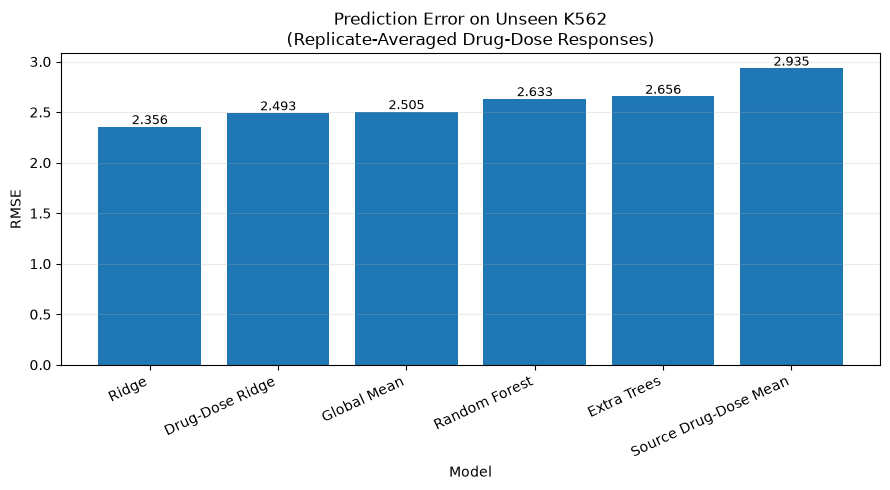

In [13]:
plot_results = (
    replicate_averaged_results
    .sort_values("RMSE")
    .reset_index(drop=True)
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    plot_results["model"],
    plot_results["RMSE"]
)

plt.ylabel("RMSE")
plt.xlabel("Model")

plt.title(
    "Prediction Error on Unseen K562\n"
    "(Replicate-Averaged Drug-Dose Responses)"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.25
)

for bar, value in zip(bars, plot_results["RMSE"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.025,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "phase3_model_rmse_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

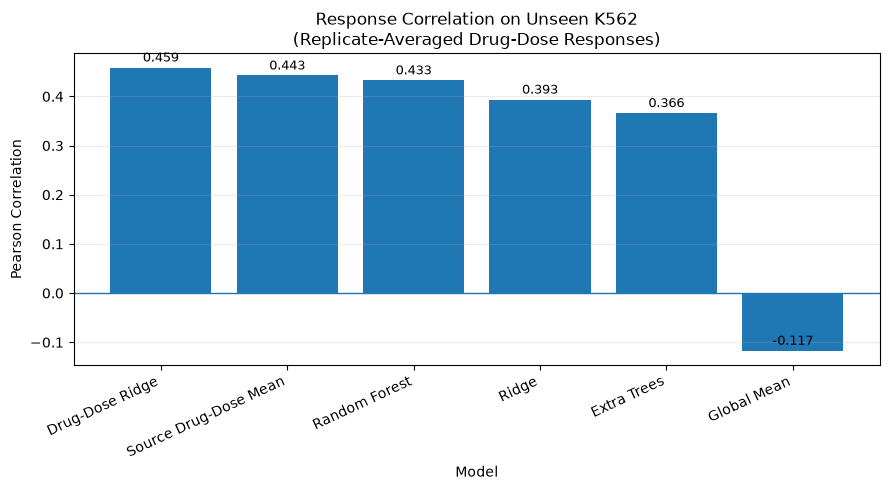

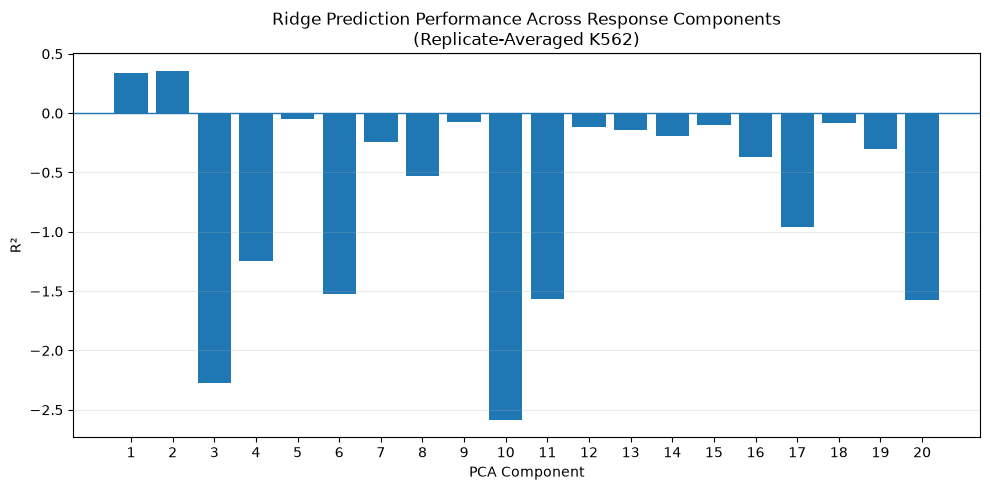

Saved both diagnostic figures.


In [14]:
pearson_plot = (
    replicate_averaged_results
    .sort_values("Pearson", ascending=False)
    .reset_index(drop=True)
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    pearson_plot["model"],
    pearson_plot["Pearson"]
)

plt.ylabel("Pearson Correlation")
plt.xlabel("Model")

plt.title(
    "Response Correlation on Unseen K562\n"
    "(Replicate-Averaged Drug-Dose Responses)"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.axhline(
    0,
    linewidth=1
)

plt.grid(
    axis="y",
    alpha=0.25
)

for bar, value in zip(
    bars,
    pearson_plot["Pearson"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.012,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "phase3_model_pearson_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.figure(figsize=(10, 5))

plt.bar(
    ridge_per_pc["PC"],
    ridge_per_pc["R2"]
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("PCA Component")
plt.ylabel("R²")

plt.title(
    "Ridge Prediction Performance Across Response Components\n"
    "(Replicate-Averaged K562)"
)

plt.xticks(
    ridge_per_pc["PC"]
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "phase3_ridge_per_pc_r2.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved both diagnostic figures.")

## Per-drug results

In [15]:
ridge_avg_df = pd.DataFrame(
    ridge_avg,
    columns=pc_cols
)

ridge_avg_df["drug_dose_key"] = Y_test_avg_df.index

drug_lookup = (
    test_meta[
        ["drug_dose_key", "product_name", "dose"]
    ]
    .drop_duplicates("drug_dose_key")
    .set_index("drug_dose_key")
)

true_avg_df = Y_test_avg_df.copy()

drug_lookup = drug_lookup.loc[
    true_avg_df.index
]

per_drug_rows = []

for drug in sorted(
    drug_lookup["product_name"].unique()
):

    drug_keys = drug_lookup[
        drug_lookup["product_name"] == drug
    ].index

    y_true_drug = (
        true_avg_df
        .loc[drug_keys]
        .to_numpy()
    )

    y_pred_drug = (
        ridge_avg_df
        .set_index("drug_dose_key")
        .loc[drug_keys, pc_cols]
        .to_numpy()
    )

    rmse = np.sqrt(
        np.mean(
            (y_true_drug - y_pred_drug) ** 2
        )
    )

    pearson = np.corrcoef(
        y_true_drug.ravel(),
        y_pred_drug.ravel()
    )[0, 1]

    per_drug_rows.append({
        "drug": drug,
        "n_doses": len(drug_keys),
        "RMSE": rmse,
        "Pearson": pearson
    })

per_drug_results = pd.DataFrame(
    per_drug_rows
)

print("Number of evaluated drugs:", len(per_drug_results))

print("\n=== BEST 10 DRUGS BY RIDGE RMSE ===")

display(
    per_drug_results
    .sort_values("RMSE")
    .head(10)
    .round(4)
)

print("\n=== WORST 10 DRUGS BY RIDGE RMSE ===")

display(
    per_drug_results
    .sort_values("RMSE", ascending=False)
    .head(10)
    .round(4)
)

print("\n=== BEST 10 DRUGS BY PEARSON ===")

display(
    per_drug_results
    .sort_values("Pearson", ascending=False)
    .head(10)
    .round(4)
)

Number of evaluated drugs: 188

=== BEST 10 DRUGS BY RIDGE RMSE ===


,drug,n_doses,RMSE,Pearson
149,SRT2104 (GSK2245840),4,1.2749,0.4520
171,Tranylcypromine (2-PCPA) HCl,4,1.3863,0.4536
105,Mesna,4,1.3865,0.4343
162,Tazemetostat (EPZ-6438),4,1.4779,0.2996
7,AICAR (Acadesine),4,1.5102,0.2619
178,UNC1999,4,1.5157,0.3942
76,GSK-LSD1 2HCl,4,1.5176,0.1542
159,TMP195,4,1.5376,0.3219
44,"Cerdulatinib (PRT062070, PRT2070)",4,1.5545,0.1510
36,CEP-33779,4,1.5571,0.2229



=== WORST 10 DRUGS BY RIDGE RMSE ===


,drug,n_doses,RMSE,Pearson
71,Flavopiridol HCl,4,5.2391,0.5639
96,"Luminespib (AUY-922, NVP-AUY922)",4,4.6134,0.5753
124,"Patupilone (EPO906, Epothilone B)",4,4.1788,0.1982
10,AT9283,4,4.1125,0.2653
170,Trametinib (GSK1120212),4,3.7046,0.1285
185,YM155 (Sepantronium Bromide),4,3.6355,0.5851
33,Bisindolylmaleimide IX (Ro 31-8220 Mesylate),3,3.4865,0.1696
34,Bosutinib (SKI-606),4,3.4470,0.2331
175,Tucidinostat (Chidamide),4,3.3142,0.3669
173,Trichostatin A (TSA),4,3.2707,0.5968



=== BEST 10 DRUGS BY PEARSON ===


,drug,n_doses,RMSE,Pearson
130,Quisinostat (JNJ-26481585) 2HCl,4,3.0234,0.8965
123,Panobinostat (LBH589),4,2.7621,0.8964
51,Dacinostat (LAQ824),4,2.7806,0.8804
38,CUDC-907,4,2.9121,0.8351
127,Pracinostat (SB939),4,3.1846,0.7488
79,Givinostat (ITF2357),4,2.9268,0.7259
13,Abexinostat (PCI-24781),4,3.0879,0.7153
9,AR-42,4,2.6551,0.6954
32,Belinostat (PXD101),4,2.8351,0.6571
64,Entinostat (MS-275),4,2.5118,0.6474


## Save

In [16]:
k562_results.to_csv(
    TABLES_DIR / "phase3_model_results_k562.csv",
    index=False
)

replicate_averaged_results.to_csv(
    TABLES_DIR / "phase3_model_results_k562_replicate_averaged.csv",
    index=False
)

ridge_validation.to_csv(
    TABLES_DIR / "phase3_ridge_validation.csv",
    index=False
)

rf_validation.to_csv(
    TABLES_DIR / "phase3_random_forest_validation.csv",
    index=False
)

interaction_validation.to_csv(
    TABLES_DIR / "phase3_drug_dose_ridge_validation.csv",
    index=False
)

et_validation.to_csv(
    TABLES_DIR / "phase3_extra_trees_validation.csv",
    index=False
)

ridge_per_pc.to_csv(
    TABLES_DIR / "phase3_ridge_per_pc_results.csv",
    index=False
)

per_drug_results.to_csv(
    TABLES_DIR / "phase3_ridge_per_drug_results.csv",
    index=False
)

np.save(
    PROCESSED_DIR / "phase3_pred_ridge_k562.npy",
    pred_ridge
)

np.save(
    PROCESSED_DIR / "phase3_pred_drug_dose_ridge_k562.npy",
    pred_interaction_ridge
)

np.save(
    PROCESSED_DIR / "phase3_pred_random_forest_k562.npy",
    pred_rf
)

np.save(
    PROCESSED_DIR / "phase3_pred_extra_trees_k562.npy",
    pred_et
)

np.save(
    PROCESSED_DIR / "phase3_k562_replicate_averaged_truth.npy",
    Y_test_avg
)

np.save(
    PROCESSED_DIR / "phase3_k562_replicate_averaged_ridge.npy",
    ridge_avg
)

print("Saved all tables and predictions.")

Saved all tables and predictions.
